# Food inflation in Turkey: exploration and regression

How did monthly food inflation in Turkey move with the USD/TRY rate and global food prices?

- **Window:** statistics, figures and regressions use months through **December 2023**. Only the coverage checks count later data, which is reserved for forecasting.
- **Sample windows:** results are shown for 2005–2023 and for 2005–2020, before the high-inflation years.
- **No forecasts:** this notebook fits no forecasting models and builds no forecast splits or features. In-sample fit says nothing about forecast accuracy.

## Setup

Run `uv run food-inflation-download` and `uv run food-inflation-prepare` first, as described in the README. The written observations describe the proposal snapshots. After refreshing the inputs, rerun the notebook and check them against the new outputs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import durbin_watson

from food_inflation.monthly_dataset.build import load_sources, monthly_indicators

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
raw_dir = project_root / "data" / "raw"
monthly_path = project_root / "data" / "interim" / "monthly_indicators.parquet"

ANALYSIS_END = "2023-12"
THRESHOLD_END = "2020-12"
LAG = 1
HAC_LAGS = 6

In [2]:
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "lines.linewidth": 1.4,
})
pd.set_option("display.float_format", "{:.3g}".format)

## Load the data

The saved monthly table must match a fresh preparation of the source CSVs.

In [3]:
cpi, usd_try_daily, fao = load_sources(raw_dir)
monthly = pd.read_parquet(monthly_path)
pd.testing.assert_frame_equal(monthly, monthly_indicators(cpi, usd_try_daily, fao), check_freq=False)

In [4]:
labels = {
    "food_cpi": "Food CPI",
    "cereals_cpi": "Bread and cereals CPI",
    "meat_cpi": "Meat CPI",
    "dairy_eggs_cpi": "Milk, cheese and eggs CPI",
    "oils_fats_cpi": "Oils and fats CPI",
    "usd_try": "USD/TRY",
    "fao_food_price_index": "FAO Food Price Index",
    "fao_meat": "FAO meat",
    "fao_dairy": "FAO dairy",
    "fao_cereals": "FAO cereals",
    "fao_vegetable_oils": "FAO vegetable oils",
    "fao_sugar": "FAO sugar",
}

## Data quality

### Coverage

Source rows cover all available dates. The last column counts nonmissing monthly values through December 2023.

In [5]:
def coverage(table: pd.DataFrame, source: str, frequency: str) -> pd.DataFrame:
    rows = {}
    for column in table:
        values = table[column]
        rows[(source, labels[column])] = {
            "Frequency": frequency,
            "First value": values.first_valid_index().date(),
            "Last value": values.last_valid_index().date(),
            "Rows": len(values),
            "Missing": int(values.isna().sum()),
        }
    return pd.DataFrame.from_dict(rows, orient="index")

In [6]:
source_coverage = pd.concat([
    coverage(cpi, "Turkish CPI", "Monthly"),
    coverage(usd_try_daily, "USD/TRY", "Daily"),
    coverage(fao.add_prefix("fao_"), "FAO", "Monthly"),
])
source_coverage["Monthly rows to Dec 2023"] = [
    int(monthly.loc[:ANALYSIS_END, column].notna().sum()) for column in [*cpi, *usd_try_daily, *("fao_" + fao.columns)]
]
source_coverage

Frequency First value  Last value  Rows  \
Turkish CPI Food CPI                    Monthly  2005-01-01  2026-09-01   261   
            Bread and cereals CPI       Monthly  2005-01-01  2026-09-01   261   
            Meat CPI                    Monthly  2005-01-01  2026-09-01   261   
            Milk, cheese and eggs CPI   Monthly  2005-01-01  2026-09-01   261   
            Oils and fats CPI           Monthly  2005-01-01  2026-09-01   261   
USD/TRY     USD/TRY                       Daily  2005-01-03  2026-09-30  7943   
FAO         FAO Food Price Index        Monthly  1990-01-01  2026-09-01   441   
            FAO meat                    Monthly  1990-01-01  2026-09-01   441   
            FAO dairy                   Monthly  1990-01-01  2026-09-01   441   
            FAO cereals                 Monthly  1990-01-01  2026-09-01   441   
            FAO vegetable oils          Monthly  1990-01-01  2026-09-01   441   
            FAO sugar                   Monthly  1990-01-01  2026-09-01   441   

                                       Missing  Monthly rows to Dec 2023  
Turkish CPI Food CPI                         0                       228  
            Bread and cereals CPI            0                       228  
            Meat CPI                         0                       228  
            Milk, cheese and eggs CPI        0                       228  
            Oils and fats CPI                0                       228  
USD/TRY     USD/TRY                       2470                       228  
FAO         FAO Food Price Index             0                       228  
            FAO meat                         0                       228  
            FAO dairy                        0                       228  
            FAO cereals                      0                       228  
            FAO vegetable oils               0                       228  
            FAO sugar                        0                       228

All missing source values are daily USD/TRY rates. The monthly table is complete through December 2023.

### CPI rounding

EVDS publishes CPI levels with two decimals on a 2025 = 100 base, so early levels are small. The table shows one 0.01 step as a share of the food CPI level.

In [7]:
food_level = monthly.loc[:ANALYSIS_END, "food_cpi"]
food_level_change = food_level.diff().loc["2005-02":]
rounding = pd.DataFrame({
    "Median food CPI level": food_level.groupby(food_level.index.year).median(),
    "One 0.01 step (% of level)": (0.01 / food_level * 100).groupby(food_level.index.year).median(),
    "Months with no change": (food_level_change == 0).groupby(food_level_change.index.year).sum(),
})
rounding.index.name = "Year"
rounding.loc[[2005, 2008, 2012, 2016, 2020, 2022, 2023]]

,Median food CPI level,One 0.01 step (% of level),Months with no change
Year,,,
2005,2.5,0.4,3
2008,3.47,0.288,2
2012,4.82,0.207,2
2016,6.92,0.145,0
2020,12.4,0.0808,0
2022,29.4,0.0341,0
2023,46.2,0.0217,0


One step is 0.40% of the level in 2005, 0.08% in 2020 and 0.02% in 2023. Monthly changes before about 2012 are coarse, and all nine months with zero change fall in 2005–2014. The four CPI subcategories have the same issue.

### Missing daily rates

In [8]:
rate_missing = usd_try_daily["usd_try"].isna()
weekend = usd_try_daily.index.day_of_week >= 5
pd.DataFrame({
    "Published": [int((~rate_missing & ~weekend).sum()), int((~rate_missing & weekend).sum())],
    "Missing": [int((rate_missing & ~weekend).sum()), int((rate_missing & weekend).sum())],
}, index=["Weekdays", "Weekends"])

,Published,Missing
Weekdays,5473,200
Weekends,0,2270


### Weekday gaps by calendar date

Calendar dates with weekday gaps in at least five years.

In [9]:
weekday_gaps = usd_try_daily.index[rate_missing & ~weekend]
gap_dates = pd.Series(weekday_gaps.strftime("%d %b"), index=weekday_gaps)
gap_years = gap_dates.groupby(gap_dates.to_numpy()).agg(
    Years="size",
    First=lambda dates: dates.index.min().year,
    Last=lambda dates: dates.index.max().year,
).sort_values("Years", ascending=False)
recurring = gap_years[gap_years["Years"] >= 5]
print(f"Weekday gaps: {len(weekday_gaps)} days on {len(gap_years)} distinct calendar dates")
print(f"Gaps on the {len(recurring)} dates that recur in at least 5 years: {recurring['Years'].sum()}")
recurring

Weekday gaps: 200 days on 113 distinct calendar dates
Gaps on the 7 dates that recur in at least 5 years: 91


,Years,First,Last
19 May,16,2005,2026
23 Apr,14,2007,2026
29 Oct,14,2007,2025
30 Aug,14,2005,2024
01 Jan,14,2007,2026
01 May,12,2009,2026
15 Jul,7,2019,2026


- **Weekends:** no rate is published, so all 2,270 weekend days are blank.
- **Recurring dates:** 91 of the 200 weekday gaps fall on seven fixed dates that coincide with public holidays. Individual closures are unverified.
- **Other dates:** the remaining 109 gaps fall on 106 dates with unverified causes.

The 15 July gaps start in 2019 because 15 July fell on a weekend in 2017 and 2018.

### Published rates per month

Months counted by the number of rates in their USD/TRY average.

In [10]:
rates_per_month = usd_try_daily["usd_try"].resample("MS").count()
rate_count_table = pd.DataFrame({
    "All months": rates_per_month.value_counts().sort_index(),
    "Months to Dec 2023": rates_per_month.loc[:ANALYSIS_END].value_counts().sort_index(),
}).fillna(0).astype(int)
rate_count_table.index.name = "Published rates"
print("Fewest published rates:", rates_per_month.idxmin().strftime("%B %Y"), int(rates_per_month.min()))
rate_count_table.T

Fewest published rates: May 2026 16


Published rates,16,17,18,19,20,21,22,23
All months,1,4,11,12,52,82,76,23
Months to Dec 2023,0,3,10,11,46,72,64,22


Every month has 16–23 published rates, and every month through December 2023 has at least 17.

## Month-over-month changes

Changes are percentages, $100 \times (x_t / x_{t-1} - 1)$, from February 2005 to December 2023.

### Calendar check

Every change must compare adjacent months, so the window needs one complete row per month.

In [11]:
calendar = monthly.loc[:ANALYSIS_END]
expected_months = pd.date_range("2005-01", ANALYSIS_END, freq="MS")
assert calendar.index.equals(expected_months) and not calendar.isna().any().any(), (
    "The historical monthly table needs one complete row per month from January 2005 through December 2023."
)

### Changes and periods

In [12]:
changes = calendar.pct_change(fill_method=None) * 100
analysis = changes.iloc[1:]
annual = calendar.pct_change(12, fill_method=None) * 100
period = pd.Series(
    np.where(analysis.index <= THRESHOLD_END, "2005–2020", "2021–2023"), index=analysis.index
)
print(f"Analysis window: {analysis.index.min():%B %Y} to {analysis.index.max():%B %Y}, {len(analysis)} months")

Analysis window: February 2005 to December 2023, 227 months


### Summary by period

In [13]:
headline = ["food_cpi", "usd_try", "fao_food_price_index"]
headline_summary = pd.concat({
    name: frame[headline].rename(columns=labels).agg(["count", "mean", "median", "std", "min", "max"])
    for name, frame in [
        ("2005–2023", analysis),
        ("2005–2020", analysis[period == "2005–2020"]),
        ("2021–2023", analysis[period == "2021–2023"]),
    ]
}).round(2)
headline_summary.index.names = ["Period", "Statistic (% per month)"]
headline_summary

Food CPI  USD/TRY  FAO Food Price Index
Period    Statistic (% per month)                                         
2005–2023 count                         227      227                   227
          mean                         1.44     1.45                   0.3
          median                       1.16     0.78                   0.1
          std                          2.68     4.43                  2.82
          min                         -6.56    -8.29                 -13.3
          max                            16     28.6                  13.1
2005–2020 count                         191      191                   191
          mean                         0.91     0.99                   0.3
          median                       0.78     0.41                  0.14
          std                          2.08      3.8                  2.71
          min                         -6.56    -8.29                 -13.3
          max                          6.41     20.7                   7.8
2021–2023 count                          36       36                    36
          mean                         4.26     3.92                  0.31
          median                       3.17     1.87                 -0.47
          std                           3.6      6.4                  3.41
          min                          0.34    -4.35                 -9.06
          max                            16     28.6                  13.1

### Changes over time

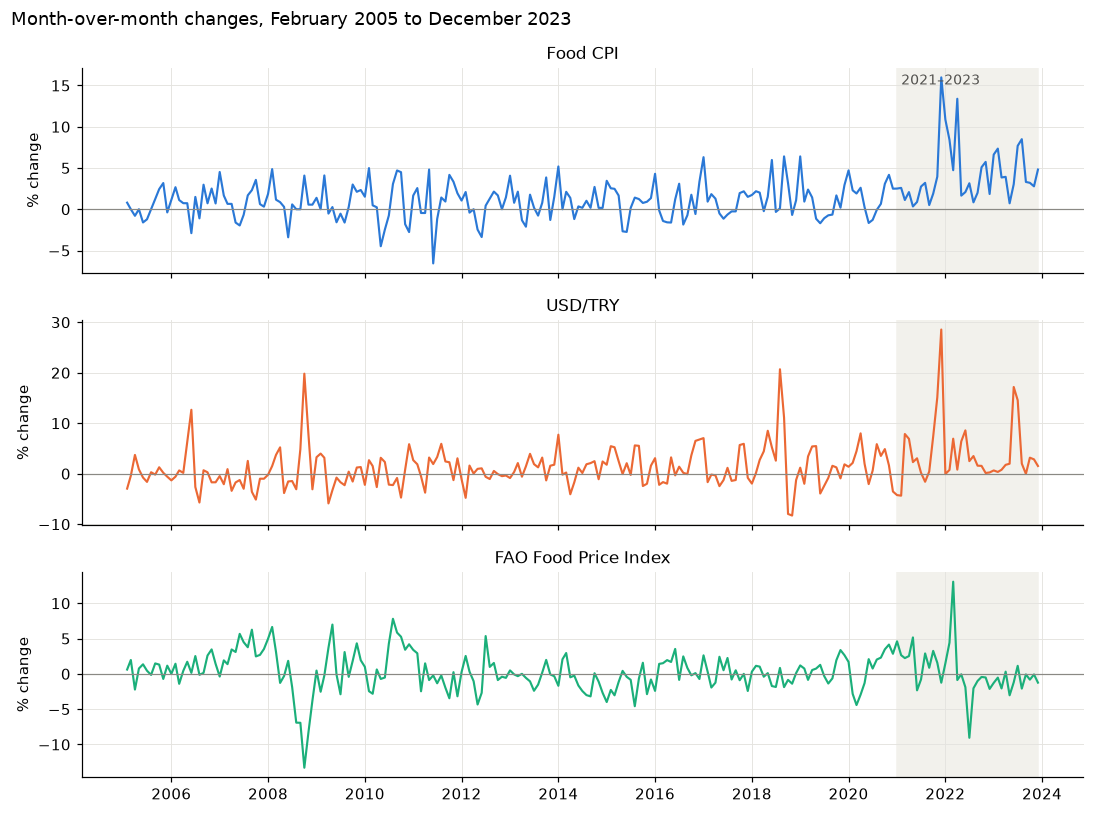

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for ax, column, color in zip(axes, headline, [BLUE, ORANGE, AQUA]):
    ax.plot(analysis.index, analysis[column], color=color)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.axvspan(pd.Timestamp("2021-01-01"), analysis.index.max(), color="#f2f1ec", zorder=0)
    ax.set_title(labels[column])
    ax.set_ylabel("% change")
axes[0].annotate("2021–2023", xy=(pd.Timestamp("2021-02-01"), 0.92), xycoords=("data", "axes fraction"),
                 fontsize=9, color="#52514e")
fig.suptitle("Month-over-month changes, February 2005 to December 2023", x=0.01, ha="left")
fig.tight_layout()
plt.show()

**Figure 1.** Monthly changes, each panel on its own scale. Shading marks 2021–2023.

- **Food CPI:** the mean rose from 0.91% per month in 2005–2020 to 4.26% in 2021–2023, and the median from 0.78% to 3.17%. Every month in 2021–2023 rose, with peaks of 15.98% in December 2021 and 13.39% in April 2022.
- **USD/TRY:** the mean rose from 0.99% to 3.92%. Spikes cluster in October 2008 (+19.8%), August 2018 (+20.7%), December 2021 (+28.6%) and June 2023 (+17.2%).
- **FAO:** the mean stayed near 0.30% in both periods. It fell in late 2008 as the lira weakened and peaked at +13.1% in March 2022.

### Distributions

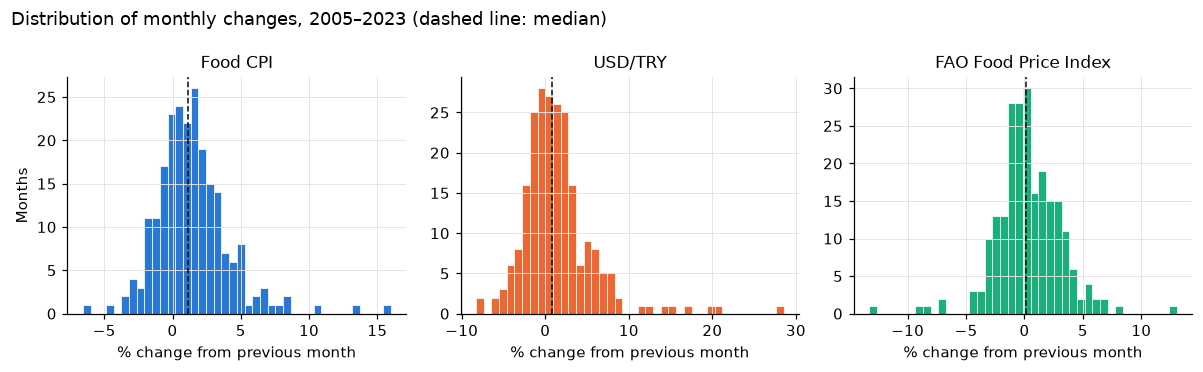

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, column, color in zip(axes, headline, [BLUE, ORANGE, AQUA]):
    values = analysis[column]
    ax.hist(values, bins=40, color=color, edgecolor="white", linewidth=0.5)
    ax.axvline(values.median(), color="#0b0b0b", linewidth=1, linestyle="--")
    ax.set_title(labels[column])
    ax.set_xlabel("% change from previous month")
axes[0].set_ylabel("Months")
fig.suptitle("Distribution of monthly changes, 2005–2023 (dashed line: median)", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [16]:
skew = analysis[headline].rename(columns=labels).agg(["skew", "kurt"]).T.round(2)
skew.columns = ["Skewness", "Excess kurtosis"]
skew

,Skewness,Excess kurtosis
Food CPI,1.39,5.5
USD/TRY,2.14,8.81
FAO Food Price Index,-0.17,4.08


**Figure 2.** All three distributions have heavy tails. Food CPI and USD/TRY are right-skewed (1.39 and 2.14); FAO is roughly symmetric. Because a few months can drive Pearson correlations and OLS fits, later sections also report Spearman correlations and a 2005–2020 refit.

### Seasonality

In [17]:
month_names = pd.date_range("2000-01-01", periods=12, freq="MS").strftime("%b")
food_by_month = [analysis.loc[analysis.index.month == m, "food_cpi"] for m in range(1, 13)]

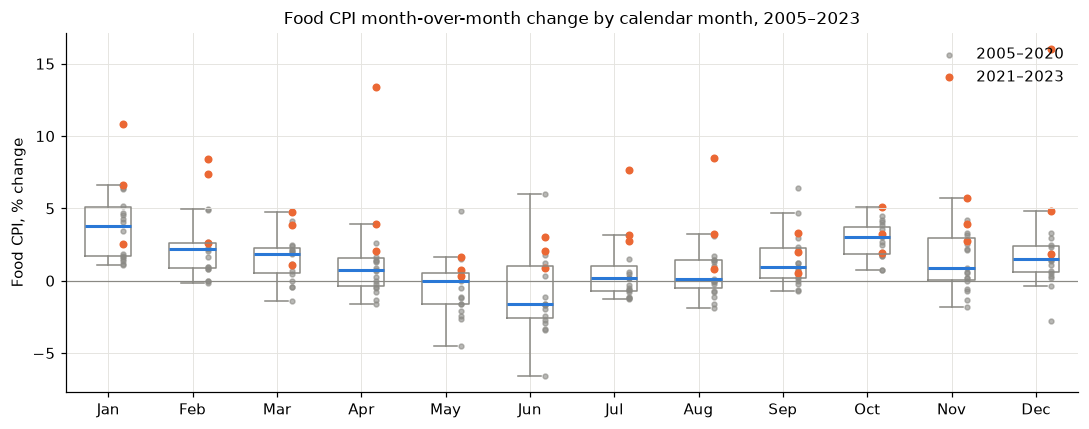

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(food_by_month, tick_labels=month_names, widths=0.55, showfliers=False,
           medianprops={"color": BLUE, "linewidth": 2}, boxprops={"color": GREY},
           whiskerprops={"color": GREY}, capprops={"color": GREY})
for m, values in enumerate(food_by_month, start=1):
    early = values[values.index <= THRESHOLD_END]
    late = values[values.index > THRESHOLD_END]
    ax.scatter(np.full(len(early), m) + 0.18, early, s=10, color=GREY, alpha=0.6,
               label="2005–2020" if m == 1 else None)
    ax.scatter(np.full(len(late), m) + 0.18, late, s=18, color=ORANGE,
               label="2021–2023" if m == 1 else None)
ax.axhline(0, color=GREY, linewidth=0.8)
ax.set_ylabel("Food CPI, % change")
ax.set_title("Food CPI month-over-month change by calendar month, 2005–2023")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

In [19]:
seasonal = analysis[period == "2005–2020"].groupby(analysis.index[period == "2005–2020"].month)["food_cpi"]
seasonality_table = pd.DataFrame({
    "Median 2005–2020": seasonal.median(),
    "Share of falls 2005–2020": seasonal.apply(lambda values: (values < 0).mean()),
    "Median 2005–2023": analysis.groupby(analysis.index.month)["food_cpi"].median(),
}, index=range(1, 13))
seasonality_table.index = month_names
seasonality_table.round(2).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Median 2005–2020,3.45,1.87,1.49,0.44,-0.83,-1.68,-0.43,0,0.86,2.85,0.59,1.4
Share of falls 2005–2020,0,0.06,0.19,0.38,0.56,0.75,0.56,0.44,0.19,0,0.25,0.12
Median 2005–2023,3.76,2.18,1.83,0.74,0,-1.6,0.16,0.11,0.93,3,0.91,1.5


**Figure 3.** Boxes show the 2005–2023 spread for each calendar month, without outliers. Dots are individual years; orange marks 2021–2023. The table uses 2005–2020 so the high-inflation years do not dominate.

- **Rises:** January had the highest 2005–2020 median (+3.45%), then October (+2.85%). Neither fell in any year.
- **Falls:** June had the lowest median (−1.68%) and fell in 75% of years. May fell in 56%.
- **2021–2023:** changes sat higher in every month but kept the seasonal shape.

The regressions below have no calendar-month terms, so this seasonality stays in their residuals.

## Lagged relationships

The regressions use a **one-month lag** of USD/TRY and FAO changes. Cross-correlations at lags 0–6 show how the association varies with the lag. A forecast would need a separate check of publication dates.

In [20]:
lags = range(0, 7)
cross_correlation = pd.DataFrame({
    labels[column]: [analysis["food_cpi"].corr(changes[column].shift(lag).loc[analysis.index]) for lag in lags]
    for column in ["usd_try", "fao_food_price_index"]
}, index=pd.Index(lags, name="Lag (months)"))

lagged = pd.DataFrame({
    "food": analysis["food_cpi"],
    "fx_lag": changes["usd_try"].shift(LAG).loc[analysis.index],
    "fao_lag": changes["fao_food_price_index"].shift(LAG).loc[analysis.index],
    "period": period,
}).dropna()

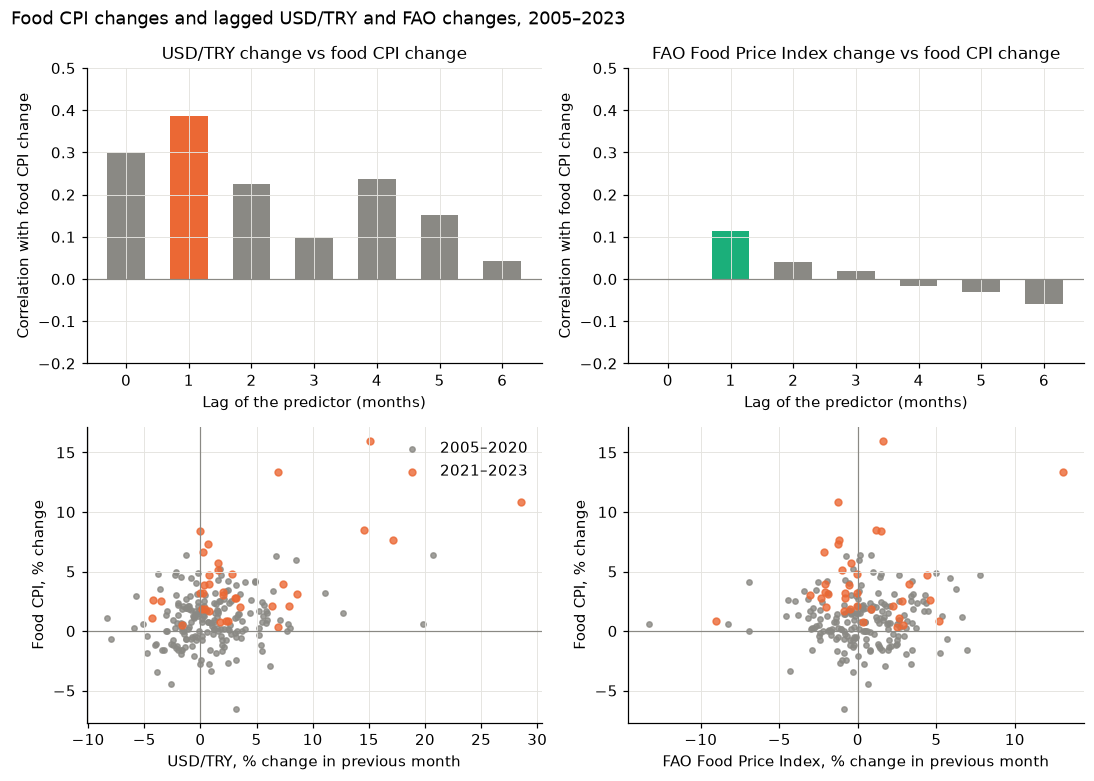

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2))
for ax, column, color in zip(axes[0], ["usd_try", "fao_food_price_index"], [ORANGE, AQUA]):
    values = cross_correlation[labels[column]]
    ax.bar(values.index, values, color=[color if lag == LAG else GREY for lag in values.index], width=0.6)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set_ylim(-0.2, 0.5)
    ax.set_xlabel("Lag of the predictor (months)")
    ax.set_ylabel("Correlation with food CPI change")
    ax.set_title(f"{labels[column]} change vs food CPI change")
for ax, column, name in zip(axes[1], ["fx_lag", "fao_lag"], ["USD/TRY", "FAO Food Price Index"]):
    for label, color, size in [("2005–2020", GREY, 12), ("2021–2023", ORANGE, 20)]:
        subset = lagged[lagged["period"] == label]
        ax.scatter(subset[column], subset["food"], s=size, color=color, alpha=0.8, label=label)
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.set_xlabel(f"{name}, % change in previous month")
    ax.set_ylabel("Food CPI, % change")
axes[1, 0].legend(frameon=False)
fig.suptitle("Food CPI changes and lagged USD/TRY and FAO changes, 2005–2023", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [22]:
cross_correlation.round(3).T

Lag (months),0,1,2,3,4,5,6
USD/TRY,0.299,0.387,0.224,0.097,0.236,0.152,0.042
FAO Food Price Index,-0.003,0.113,0.04,0.018,-0.017,-0.031,-0.06


In [23]:
lagged_correlation = pd.DataFrame({
    name: {
        "Months": len(frame),
        "USD/TRY (lag 1)": frame["food"].corr(frame["fx_lag"]),
        "FAO (lag 1)": frame["food"].corr(frame["fao_lag"]),
        "USD/TRY (lag 1), Spearman": frame["food"].corr(frame["fx_lag"], method="spearman"),
        "FAO (lag 1), Spearman": frame["food"].corr(frame["fao_lag"], method="spearman"),
    }
    for name, frame in [("2005–2023", lagged), *lagged.groupby("period")]
})
lagged_correlation

,2005–2023,2005–2020,2021–2023
Months,226,190,36
USD/TRY (lag 1),0.387,0.19,0.575
FAO (lag 1),0.113,0.0615,0.263
"USD/TRY (lag 1), Spearman",0.216,0.155,0.278
"FAO (lag 1), Spearman",0.0192,0.0555,-0.102


**Figure 4.** Top: correlations with predictor changes 0–6 months earlier; lag 1 is highlighted. Bottom: one dot per month against the previous month's predictor change.

- **USD/TRY:** 0.39 at lag 1 and 0.30 at lag 0; 0.19 in 2005–2020 and 0.58 in 2021–2023. Spearman is 0.22, so a few large months, mostly after 2020, drive much of the Pearson value.
- **FAO:** 0.11 at lag 1 and near zero at other lags; Spearman is 0.02 and 2005–2020 is 0.06. One pair carries much of it: FAO +13.1% in March 2022, food CPI +13.4% in April 2022.

## Subcategories

Four Turkish CPI categories are paired with the closest FAO sub-index. The pairs are approximate: Turkish CPI tracks consumer prices and FAO tracks export prices. FAO sugar has no counterpart. The figure uses 12-month changes; the table uses monthly changes.

In [24]:
pairs = {
    "Cereals": ("cereals_cpi", "fao_cereals"),
    "Meat": ("meat_cpi", "fao_meat"),
    "Dairy and eggs": ("dairy_eggs_cpi", "fao_dairy"),
    "Oils and fats": ("oils_fats_cpi", "fao_vegetable_oils"),
}
annual_window = annual.loc["2006-01":]

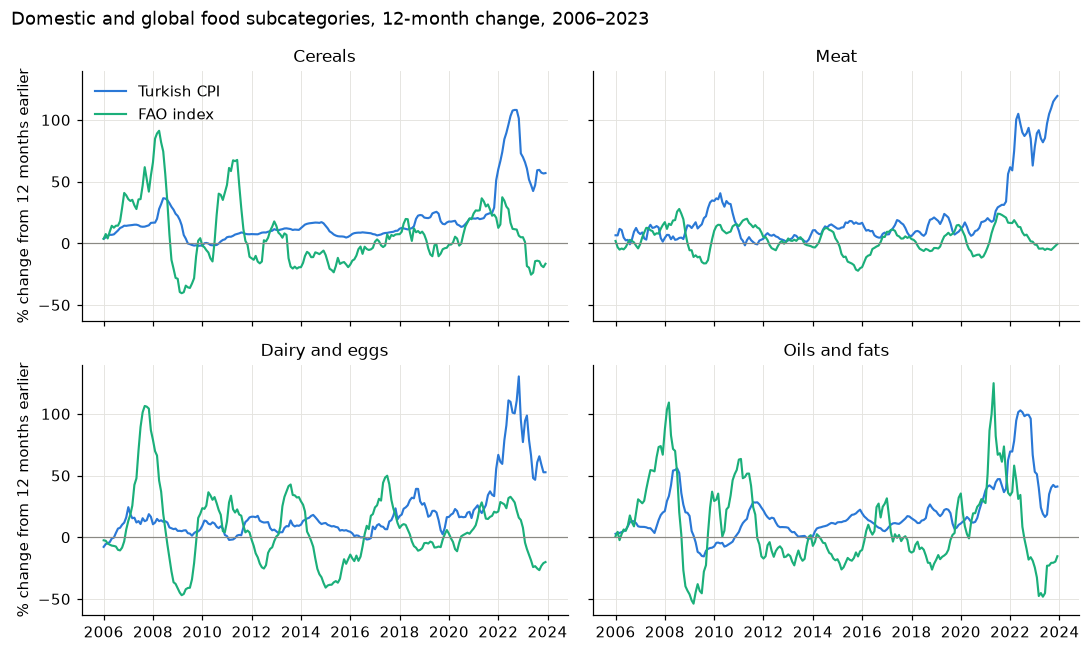

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for ax, (name, (domestic, world)) in zip(axes.flat, pairs.items()):
    ax.plot(annual_window.index, annual_window[domestic], color=BLUE, label="Turkish CPI")
    ax.plot(annual_window.index, annual_window[world], color=AQUA, label="FAO index")
    ax.axhline(0, color=GREY, linewidth=0.8)
    ax.set_title(name)
for ax in axes[:, 0]:
    ax.set_ylabel("% change from 12 months earlier")
axes[0, 0].legend(frameon=False, loc="upper left")
fig.suptitle("Domestic and global food subcategories, 12-month change, 2006–2023", x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [26]:
subcategory_table = pd.DataFrame({
    name: {
        "Turkish CPI mean % per month": analysis[domestic].mean(),
        "FAO mean % per month": analysis[world].mean(),
        "Correlation, same month": analysis[domestic].corr(analysis[world]),
        "Correlation, FAO lag 1": analysis[domestic].corr(changes[world].shift(LAG).loc[analysis.index]),
        "Correlation, FAO lag 1, 2005–2020": analysis.loc[:THRESHOLD_END, domestic].corr(
            changes[world].shift(LAG).loc[analysis.loc[:THRESHOLD_END].index]
        ),
    }
    for name, (domestic, world) in pairs.items()
}).round(3)
subcategory_table

,Cereals,Meat,Dairy and eggs,Oils and fats
Turkish CPI mean % per month,1.41,1.56,1.43,1.41
FAO mean % per month,0.402,0.229,0.27,0.466
"Correlation, same month",0.059,0.107,0.034,0.074
"Correlation, FAO lag 1",0.123,0.072,0.053,0.25
"Correlation, FAO lag 1, 2005–2020",0.227,0.008,0.053,0.208


**Figure 5.** Turkish CPI and FAO 12-month changes, on a shared scale.

- **Levels:** Turkish categories rose 1.41–1.56% per month on average; FAO counterparts rose 0.23–0.47%. FAO swung and reversed more, as in 2008 and 2011. Turkish categories rose steadily, then sharply in 2022. In late 2023, Turkish cereals, meat and dairy were still 50–120% above a year earlier while the FAO indices were below.
- **Correlations:** same-month values are 0.03–0.11. With FAO lagged one month, oils and fats is highest (0.25), then cereals (0.12); meat and dairy stay near zero. In 2005–2020, cereals is 0.23 and oils and fats 0.21.

Traded inputs such as grain and vegetable oil appear to follow world prices more closely than meat or dairy. These correlations do not establish that link.

## Conditional rates

Borrowing the idea from Lab 2, this compares how often food CPI rose sharply after a large USD/TRY or FAO rise and after other months. These rates describe what happened; they are not causal effects.

### Thresholds

75th percentiles of monthly changes from February 2005 to December 2020, fixed before 2021–2023 is counted:

- **High food month:** food CPI change above its threshold.
- **Large lira depreciation:** previous month's USD/TRY change above its threshold.
- **Large FAO rise:** previous month's FAO change above its threshold.

In [27]:
threshold_months = analysis.loc[:THRESHOLD_END]
thresholds = threshold_months[headline].quantile(0.75).rename(labels).to_frame("75th percentile, 2005–2020 (%)")
thresholds.round(2)

,"75th percentile, 2005–2020 (%)"
Food CPI,2.12
USD/TRY,2.63
FAO Food Price Index,1.93


### Event flags

In [28]:
events = pd.DataFrame({
    "high_food": lagged["food"] > threshold_months["food_cpi"].quantile(0.75),
    "fx_jump": lagged["fx_lag"] > threshold_months["usd_try"].quantile(0.75),
    "fao_jump": lagged["fao_lag"] > threshold_months["fao_food_price_index"].quantile(0.75),
    "period": lagged["period"],
})
assert events[["high_food", "fx_jump", "fao_jump"]].dtypes.eq(bool).all()

conditions = {
    "All months": pd.Series(True, index=events.index),
    "After large lira depreciation": events["fx_jump"],
    "After no large depreciation": ~events["fx_jump"],
    "After large FAO rise": events["fao_jump"],
    "After no large FAO rise": ~events["fao_jump"],
    "After both": events["fx_jump"] & events["fao_jump"],
}

### Rates by period

In [29]:
rows = []
for period_name, mask in [("2005–2020", events["period"] == "2005–2020"),
                          ("2021–2023", events["period"] == "2021–2023"),
                          ("2005–2023", pd.Series(True, index=events.index))]:
    for condition, selected in conditions.items():
        chosen = events.loc[mask & selected, "high_food"]
        rows.append({
            "Period": period_name,
            "Condition": condition,
            "Months": len(chosen),
            "High food months": int(chosen.sum()),
            "Rate": chosen.mean() if len(chosen) else np.nan,
        })
conditional_rates = pd.DataFrame(rows).set_index(["Period", "Condition"])
conditional_rates.assign(Rate=conditional_rates["Rate"].map("{:.0%}".format))

Months  High food months Rate
Period    Condition                                                   
2005–2020 All months                        190                48  25%
          After large lira depreciation      48                14  29%
          After no large depreciation       142                34  24%
          After large FAO rise               47                15  32%
          After no large FAO rise           143                33  23%
          After both                          7                 3  43%
2021–2023 All months                         36                24  67%
          After large lira depreciation      14                10  71%
          After no large depreciation        22                14  64%
          After large FAO rise               10                 5  50%
          After no large FAO rise            26                19  73%
          After both                          4                 2  50%
2005–2023 All months                        226                72  32%
          After large lira depreciation      62                24  39%
          After no large depreciation       164                48  29%
          After large FAO rise               57                20  35%
          After no large FAO rise           169                52  31%
          After both                         11                 5  45%

Thresholds use 191 months. Rates start in March 2005, the first month with a lagged change, so 2005–2020 has 190.

| Period | Base rate | After large depreciation | Otherwise | After large FAO rise | Otherwise |
|---|---|---|---|---|---|
| 2005–2020 | 25% (48/190) | 29% (14/48) | 24% (34/142) | 32% (15/47) | 23% (33/143) |
| 2021–2023 | 67% (24/36) | 71% (10/14) | 64% (14/22) | 50% (5/10) | 73% (19/26) |

The USD/TRY difference is small in both periods. The FAO difference reverses after 2020, but only 10 months follow a large rise. Only seven 2005–2020 months followed both events (three high), too few for a stable rate.

## Explanatory regressions

OLS models of the food CPI change in month $t$, all on the same months:

1. Food CPI change in $t-1$
2. Model 1 + USD/TRY change in $t-1$
3. Model 1 + FAO change in $t-1$
4. Model 1 + both

Changes are autocorrelated and more variable after 2020, so standard errors are Newey–West (HAC) with 6 lags. Coefficients are percentage points of food inflation per 1-point change in the predictor.

### Regression data

In [30]:
regression_data = pd.DataFrame({
    "food": analysis["food_cpi"],
    "food_lag": changes["food_cpi"].shift(LAG).loc[analysis.index],
    "fx_lag": lagged["fx_lag"],
    "fao_lag": lagged["fao_lag"],
}).dropna()

### Models and coefficient table

In [31]:
formulas = {
    "1. Food lag": "food ~ food_lag",
    "2. + USD/TRY": "food ~ food_lag + fx_lag",
    "3. + FAO": "food ~ food_lag + fao_lag",
    "4. + both": "food ~ food_lag + fx_lag + fao_lag",
}

def fit_models(data: pd.DataFrame, model_formulas: dict[str, str]) -> dict:
    return {
        name: smf.ols(formula, data).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})
        for name, formula in model_formulas.items()
    }

def coefficient_table(models: dict) -> pd.DataFrame:
    terms = {"Intercept": "Intercept", "food_lag": "Food CPI change (t-1)",
             "fx_lag": "USD/TRY change (t-1)", "fao_lag": "FAO change (t-1)"}
    table = {}
    for name, model in models.items():
        column = {}
        for term, label in terms.items():
            if term in model.params:
                column[label] = f"{model.params[term]:.3f} ({model.bse[term]:.3f})"
            else:
                column[label] = ""
        column["Months"] = f"{int(model.nobs)}"
        column["R²"] = f"{model.rsquared:.3f}"
        column["Adjusted R²"] = f"{model.rsquared_adj:.3f}"
        table[name] = column
    return pd.DataFrame(table)

### Full window

Coefficients with HAC standard errors in parentheses.

In [32]:
models = fit_models(regression_data, formulas)
assert len({int(model.nobs) for model in models.values()}) == 1
print(f"Months: {regression_data.index.min():%B %Y} to {regression_data.index.max():%B %Y}, n = {len(regression_data)}")
coefficient_table(models)

Months: March 2005 to December 2023, n = 226


,1. Food lag,2. + USD/TRY,3. + FAO,4. + both
Intercept,0.832 (0.142),0.705 (0.128),0.799 (0.145),0.620 (0.144)
Food CPI change (t-1),0.429 (0.083),0.344 (0.059),0.429 (0.081),0.326 (0.057)
USD/TRY change (t-1),,0.172 (0.051),,0.207 (0.054)
FAO change (t-1),,,0.107 (0.081),0.192 (0.086)
Months,226,226,226,226
R²,0.183,0.257,0.196,0.295
Adjusted R²,0.179,0.250,0.189,0.285


### Model 4 detail

In [33]:
full = models["4. + both"]
pd.DataFrame({
    "Coefficient": full.params,
    "HAC standard error": full.bse,
    "p-value": full.pvalues.map("{:.3g}".format),
    "95% CI low": full.conf_int()[0],
    "95% CI high": full.conf_int()[1],
}).round(3)

,Coefficient,HAC standard error,p-value,95% CI low,95% CI high
Intercept,0.62,0.144,1.6e-05,0.338,0.902
food_lag,0.326,0.057,1.01e-08,0.215,0.438
fx_lag,0.207,0.054,0.000126,0.101,0.312
fao_lag,0.192,0.086,0.0251,0.024,0.359


### Residual checks

In [34]:
residual_checks = pd.DataFrame({
    name: {
        "Durbin–Watson": durbin_watson(model.resid),
        "Ljung–Box p-value, 12 lags": acorr_ljungbox(model.resid, lags=[12])["lb_pvalue"].iloc[0],
        "Residual SD, 2005–2020": model.resid.loc[:THRESHOLD_END].std(),
        "Residual SD, 2021–2023": model.resid.loc["2021":].std(),
    }
    for name, model in models.items()
}).round(3)
residual_checks

,1. Food lag,2. + USD/TRY,3. + FAO,4. + both
Durbin–Watson,2.05,2.06,2.02,2.05
"Ljung–Box p-value, 12 lags",0.003,0.004,0.003,0.004
"Residual SD, 2005–2020",2.08,2.07,2.08,2.05
"Residual SD, 2021–2023",3.34,2.94,3.25,2.74


**Full window, March 2005 to December 2023, 226 months.**

| Model | Adjusted R² | USD/TRY (SE) | FAO (SE) |
|---|---|---|---|
| 1. Food lag | 0.179 | | |
| 2. + USD/TRY | 0.250 | 0.172 (0.051) | |
| 3. + FAO | 0.189 | | 0.107 (0.081) |
| 4. + both | 0.285 | 0.207 (0.054) | 0.192 (0.086) |

- **USD/TRY:** in model 4, a 1-point larger change last month goes with about 0.2 points higher food inflation, holding the other predictors fixed.
- **FAO:** alone, it is not distinguishable from zero. With USD/TRY included, the estimate rises and its 95% interval (0.02–0.36) excludes zero. One plausible but untested reason is that FAO prices and the lira sometimes moved in opposite directions, as in late 2008.
- **Residuals:** Durbin–Watson is about 2.05, so first-order autocorrelation is small. Ljung–Box p ≈ 0.004 at 12 lags shows longer-range dependence, consistent with the seasonality in Figure 3. Model 4's residual SD is 2.74 points in 2021–2023 against 2.05 in 2005–2020, one reason for HAC errors.

### Fitted values

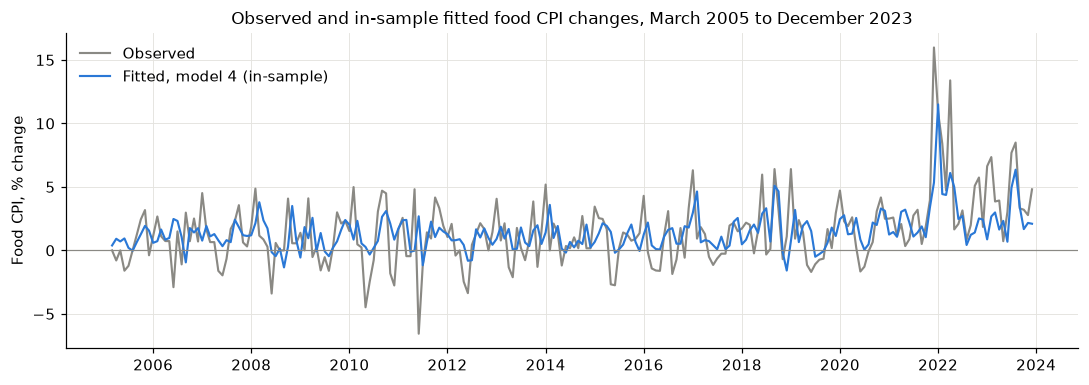

In [35]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(regression_data.index, regression_data["food"], color=GREY, label="Observed")
ax.plot(regression_data.index, full.fittedvalues, color=BLUE, label="Fitted, model 4 (in-sample)")
ax.axhline(0, color=GREY, linewidth=0.8)
ax.set_ylabel("Food CPI, % change")
ax.set_title("Observed and in-sample fitted food CPI changes, March 2005 to December 2023")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**Figure 6.** Model 4's fitted values come from the months used to estimate it. They show fit, not forecast performance.

### Sensitivity: 2005–2020 only

The large 2021–2023 changes could dominate the fit. This refit drops them.

In [36]:
early_models = fit_models(regression_data.loc[:THRESHOLD_END], formulas)
coefficient_table(early_models)

,1. Food lag,2. + USD/TRY,3. + FAO,4. + both
Intercept,0.711 (0.145),0.648 (0.137),0.697 (0.148),0.596 (0.147)
Food CPI change (t-1),0.222 (0.071),0.195 (0.074),0.222 (0.070),0.187 (0.071)
USD/TRY change (t-1),,0.086 (0.046),,0.115 (0.047)
FAO change (t-1),,,0.048 (0.048),0.107 (0.055)
Months,190,190,190,190
R²,0.049,0.073,0.053,0.090
Adjusted R²,0.044,0.063,0.043,0.075


**2005–2020, 190 months.** Every model explains much less: adjusted R² is 0.044 for the food lag and 0.075 with both predictors. The USD/TRY coefficient roughly halves to 0.115 (SE 0.047) and FAO is 0.107 (SE 0.055). Both stay positive.

### Sensitivity to seasonality

Can USD/TRY and FAO still improve the fit after accounting for the month of the year? Add a calendar-month term to the food-only model and to the model with both indicators. This lets the average level differ by month. Both fits use the same 226 months, one-month lags and HAC standard errors as before.

In [37]:
seasonal_data = regression_data.assign(calendar_month=regression_data.index.month)
seasonal_formulas = {
    name: formulas[name] + " + C(calendar_month)"
    for name in ["1. Food lag", "4. + both"]
}
seasonal_models = fit_models(seasonal_data, seasonal_formulas)
assert all(
    model.model.data.row_labels.equals(regression_data.index)
    for model in seasonal_models.values()
)

In [38]:
fit_by_seasonality = pd.DataFrame({
    "Food inflation lag": [
        models["1. Food lag"].rsquared_adj,
        seasonal_models["1. Food lag"].rsquared_adj,
    ],
    "+ USD/TRY and FAO": [
        models["4. + both"].rsquared_adj,
        seasonal_models["4. + both"].rsquared_adj,
    ],
}, index=["Without month controls", "With month controls"])
fit_by_seasonality["Gain"] = (
    fit_by_seasonality["+ USD/TRY and FAO"] - fit_by_seasonality["Food inflation lag"]
)
fit_by_seasonality.round(3)

,Food inflation lag,+ USD/TRY and FAO,Gain
Without month controls,0.179,0.285,0.106
With month controls,0.297,0.416,0.119


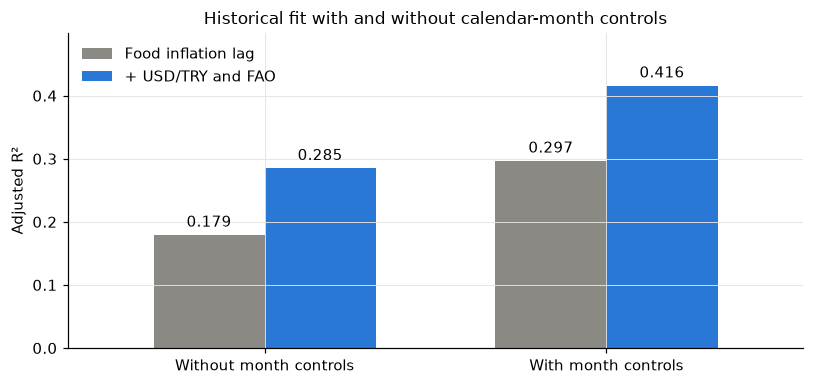

In [39]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
fit_by_seasonality[["Food inflation lag", "+ USD/TRY and FAO"]].plot.bar(
    ax=ax, color=[GREY, BLUE], rot=0, width=0.65
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)
ax.margins(y=0.2)
ax.set_ylabel("Adjusted R²")
ax.set_title("Historical fit with and without calendar-month controls")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

In [40]:
seasonal_full = seasonal_models["4. + both"]
seasonal_intervals = seasonal_full.conf_int()
seasonal_effects = pd.DataFrame({
    "Coefficient": seasonal_full.params,
    "95% CI low": seasonal_intervals[0],
    "95% CI high": seasonal_intervals[1],
}).loc[["fx_lag", "fao_lag"]]
seasonal_effects.rename(index={"fx_lag": "USD/TRY", "fao_lag": "FAO"}).round(3)

,Coefficient,95% CI low,95% CI high
USD/TRY,0.219,0.128,0.311
FAO,0.205,0.044,0.366


**Figure 7.** With calendar-month controls, adding USD/TRY and FAO raises adjusted R² from 0.297 to 0.416, a gain of 0.119. The gain without month controls is 0.106. Both estimated associations stay positive, and both 95% HAC intervals exclude zero. This check concerns fit on the observed months.

## Findings

- **Data quality:** no monthly values are missing through December 2023. Each USD/TRY average uses at least 17 rates, and 91 of 200 weekday gaps fall on seven recurring dates. The main issue is CPI rounding: before about 2012, monthly food CPI changes move in steps of 0.2–0.4 points.
- **Regime shift:** food inflation averaged 0.91% per month in 2005–2020 and 4.26% in 2021–2023, so results are reported for both windows.
- **Seasonality:** food prices usually rise in January and October and fall in May–June. USD/TRY and FAO still improve historical fit after accounting for these calendar-month differences.
- **USD/TRY:** the clearest association. The lag-1 correlation is 0.39, and adding it lifts adjusted R² from 0.179 to 0.250. In 2005–2020 it is weaker but positive (correlation 0.19, coefficient 0.115).
- **FAO:** little on its own (correlation 0.11, Spearman 0.02, adjusted R² 0.179 → 0.189). With USD/TRY, its coefficient is 0.19 and model 4 reaches 0.285. Cereals and oils and fats follow FAO more closely than meat and dairy.

### Limits

- **Not causal:** these are historical associations. Energy prices, wages, monetary policy, taxes, weather and supply shocks can move the lira and food prices together.
- **Lag choice:** one lag leaves out the USD/TRY correlations at lags 2–5 in Figure 4.
- **Dependence:** months are not independent and post-2020 variance is larger. HAC errors cover part of this, but the main models show residual dependence across the first 12 lags, so read p-values loosely.
- **No forecast claim:** all fit statistics are in-sample. Predicting months after December 2023 is left for the forecasting stage.